# ADAML Workshop 4 - RNN and LSTM

## Project Description

In this workshop, we will study RNN and LSTM by predicting the trajectory of a two-wheel-drive robot such as Roomba.

### Robot

The robot is a two wheeled robot. Each wheen can spin either forwards, backwards, or stay still. The robot moves and turns by spinning the wheels.

### Data

Each sequence starts at $(0,0)$ facing the positive x-direction. 
Each timestep the input contains:
    - Left and right wheel commands
    - A flag if the motor is running or not
    - A reset flag  (this we don't use now)
Each timestep lasts 0.1 s. Commands are held for `command_duration` timesteps (20 steps, or 2 s, in this notebook).

### Models 

The MLP, RNN, and LSTM predict the robot's 2D position $(x, y)$ after applying each timestep's command. The MLP uses only the current timestep's inputs. The RNN and LSTM also carry state from earlier timesteps. The mean baseline uses the average training trajectory.


## Tasks

1. Make sure you understand the models and the data.
    - Visualize data if needed.
2. Study how the models behave with different `sequence_length`
    - If you have time, you can study uncertainty by adding some randomness to the outputs
3. How does the LSTM memory affect the trajectory reconstruction?
4. Generalization:
    - Train the model with gentle turn and then test with sharper turns

**Each group should prepare a couple of plots to show others**


In [1]:
import time
from copy import deepcopy
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

# Dataset sizes
n_train = 4000
n_val = 1000
n_test = 1000

epochs = 80
batch_size = 128

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [2]:
# Wheel movement simulation parameters

datasets = {}
trajectories = {}

sequence_lengths = [40, 100, 200, 400]

wheel_base = 0.095       # metres
max_wheel_speed = 0.15   # metres per second
dt = 0.1                # seconds per step
command_duration = 20   # steps per command

# Simulate the longest run once so every length uses the same trajectory prefixes.
sequence_length = max(sequence_lengths)
rng = np.random.default_rng(42)
n_samples = n_train + n_val + n_test

n_commands = (
    sequence_length + command_duration - 1
) // command_duration

# How much can the robot turn and go forward
forward_command = rng.uniform(
    0.3, 0.9, size=(n_samples, n_commands)
)
turn_command = rng.uniform(
    -0.2, 0.2, size=(n_samples, n_commands)
)

wheel_commands = np.stack(
    [
        forward_command - turn_command,
        forward_command + turn_command,
    ],
    axis=-1,
)
wheel_commands = np.clip(wheel_commands, -1, 1)

active = rng.random((n_samples, n_commands)) < 0.8

wheel_commands = np.repeat(
    wheel_commands, command_duration, axis=1
)[:, :sequence_length]

active = np.repeat(
    active, command_duration, axis=1
)[:, :sequence_length]

reset = np.zeros((n_samples, sequence_length), dtype=bool)

X = np.concatenate(
    [
        wheel_commands,
        active[..., None],
        reset[..., None],
    ],
    axis=-1,
)

pose = np.zeros((n_samples, sequence_length + 1, 3))

for t in range(sequence_length):
    left_velocity = (
        max_wheel_speed * wheel_commands[:, t, 0] * active[:, t]
    )
    right_velocity = (
        max_wheel_speed * wheel_commands[:, t, 1] * active[:, t]
    )

    velocity = (left_velocity + right_velocity) / 2
    angular_velocity = (
        right_velocity - left_velocity
    ) / wheel_base

    angle_change = angular_velocity * dt
    midpoint_angle = pose[:, t, 2] + angle_change / 2

    distance = (
        velocity * dt * np.sinc(angle_change / (2 * np.pi))
    )

    pose[:, t + 1, 0] = (
        pose[:, t, 0] + distance * np.cos(midpoint_angle)
    )
    pose[:, t + 1, 1] = (
        pose[:, t, 1] + distance * np.sin(midpoint_angle)
    )
    pose[:, t + 1, 2] = pose[:, t, 2] + angle_change

# Input at step t maps to the position after that step, pose[:, t + 1].
X_full = torch.tensor(X, dtype=torch.float32)
y_full = torch.tensor(pose[:, 1:, :2], dtype=torch.float32)

for sequence_length in sequence_lengths:
    datasets[sequence_length] = (
        X_full[:, :sequence_length],
        y_full[:, :sequence_length],
    )
    trajectories[sequence_length] = pose[:, :sequence_length + 1]
    X, y = datasets[sequence_length]
    print(
        f"{sequence_length * dt:.0f} seconds: "
        f"inputs {tuple(X.shape)}, targets {tuple(y.shape)}"
    )

4 seconds: inputs (6000, 40, 4), targets (6000, 40, 2)
10 seconds: inputs (6000, 100, 4), targets (6000, 100, 2)
20 seconds: inputs (6000, 200, 4), targets (6000, 200, 2)
40 seconds: inputs (6000, 400, 4), targets (6000, 400, 2)


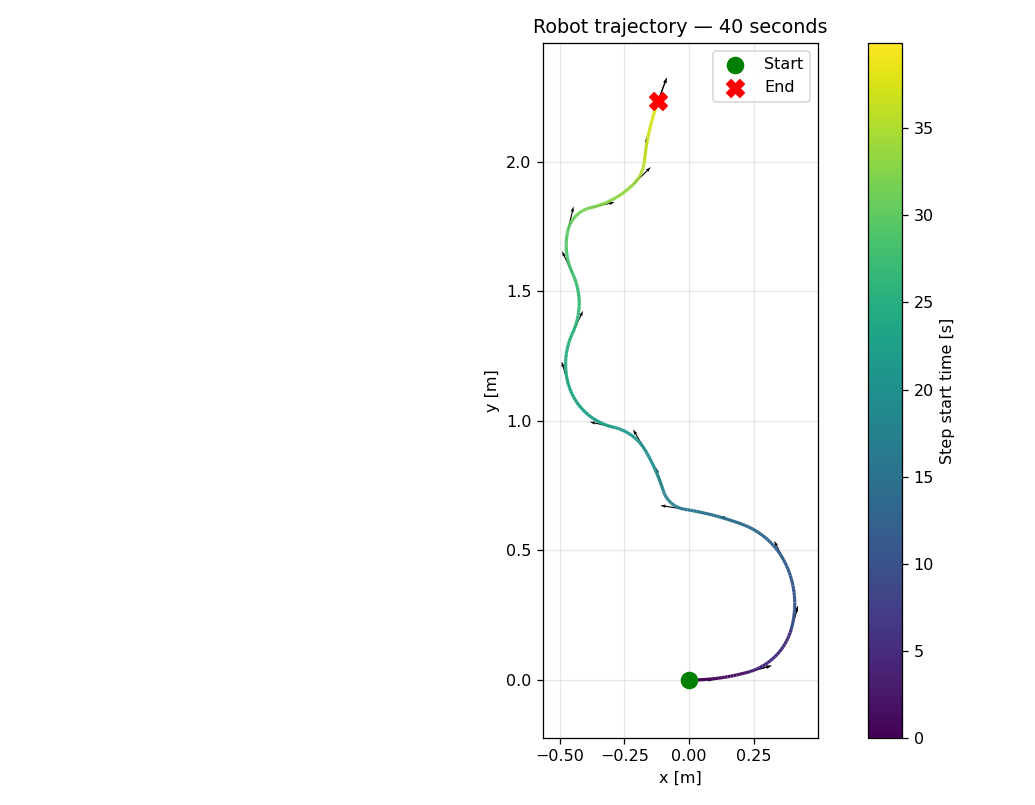

In [3]:
# Visualize a sample trajectory

from matplotlib.collections import LineCollection

sequence_length = max(sequence_lengths)
sample_index = 0

pose = trajectories[sequence_length][sample_index]
position = pose[:, :2]

segments = np.stack([position[:-1], position[1:]], axis=1)
time_step = np.arange(sequence_length) * dt

fig, ax = plt.subplots(figsize=(9, 7))

trajectory = LineCollection(
    segments,
    cmap="viridis",
    linewidths=2,
)
trajectory.set_array(time_step)
ax.add_collection(trajectory)

arrow_steps = np.arange(0, len(pose), command_duration)

ax.quiver(
    pose[arrow_steps, 0],
    pose[arrow_steps, 1],
    np.cos(pose[arrow_steps, 2]),
    np.sin(pose[arrow_steps, 2]),
    angles="xy",
    scale_units="xy",
    scale=1 / wheel_base,
    color="black",
    width=0.004,
)

ax.scatter(
    position[0, 0], position[0, 1],
    color="green", s=100, label="Start", zorder=3,
)
ax.scatter(
    position[-1, 0], position[-1, 1],
    color="red", marker="X", s=120, label="End", zorder=3,
)

ax.autoscale_view()
ax.margins(0.1)
ax.set_aspect("equal")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_title(f"Robot trajectory — {sequence_length * dt:.0f} seconds")
ax.grid(alpha=0.3)
ax.legend()

fig.colorbar(trajectory, ax=ax, label="Step start time [s]")

plt.tight_layout()
plt.show()

In [4]:
# Model definitions

# Step 1 on MLP: Modified to predict the position independently for each timestep; without using memory
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Linear(4, 64),
            nn.ReLU(),
            nn.Linear(64, 2),
        )

    def forward(self, X):
        # Linear layers act on the feature axis independently at each step.
        return self.layers(X)

# Step 1 RNN: This model was also correct from the start
class RNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=4,
            hidden_size=32,
            batch_first=True,
        )
        self.output = nn.Linear(32, 2)

    def forward(self, X):
        H, _ = self.rnn(X)
        return self.output(H)

# Step 1 LSTM: This model was also correct from the start
class LSTM(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=4,
            hidden_size=32,
            batch_first=True,
        )
        self.output = nn.Linear(32, 2)

        with torch.no_grad():
            self.lstm.bias_ih_l0[32:64] = 3.0
            self.lstm.bias_hh_l0[32:64] = 0.0

    def forward(self, X):
        H, _ = self.lstm(X)
        return self.output(H)

In [5]:
# Training and evaluation
results = {
    name: [] for name in ["Mean baseline", "MLP", "RNN", "LSTM"]
}
endpoint_errors = {name: [] for name in results}
selected_epochs = {}
validation_curves = {}
test_predictions = {}

def trajectory_metrics(prediction, target):
    error = prediction - target
    rmse = error.square().mean().sqrt().item()
    endpoint_error = error[:, -1].norm(dim=-1).mean().item()
    return rmse, endpoint_error


for sequence_length in sequence_lengths:
    X, y = datasets[sequence_length]

    n_samples = n_train + n_val + n_test
    assert X.shape == (n_samples, sequence_length, 4), X.shape
    assert y.shape == (n_samples, sequence_length, 2), y.shape

    # Split by whole trajectory. Only training rows enter the optimizer.
    val_end = n_train + n_val
    X_train = X[:n_train]
    y_train = y[:n_train]

    X_val = X[n_train:val_end]
    y_val = y[n_train:val_end]
    val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=batch_size)

    X_test = X[val_end:]
    y_test = y[val_end:]

    mean_position = y_train.mean(dim=0)
    baseline_prediction = mean_position.expand_as(y_test)
    baseline_rmse, baseline_endpoint = trajectory_metrics(baseline_prediction, y_test)

    results["Mean baseline"].append(baseline_rmse)
    endpoint_errors["Mean baseline"].append(baseline_endpoint)
    test_predictions[("Mean baseline", sequence_length)] = baseline_prediction
    print(f"Mean baseline, sequence length = {sequence_length}: test RMSE = {baseline_rmse:.4f}")

    for model_name in ["MLP", "RNN", "LSTM"]:
        torch.manual_seed(42)

        if model_name == "MLP":
            model = MLP()
        elif model_name == "RNN":
            model = RNN()
        else:
            model = LSTM()

        model = model.to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

        train_loader = DataLoader(
            TensorDataset(X_train, y_train),
            batch_size=batch_size,
            shuffle=True,
            generator=torch.Generator().manual_seed(42),
        )

        validation_losses = []
        best_val_rmse = float("inf")
        best_epoch = None
        best_weights = None

        print(f"\n{model_name}, sequence length = {sequence_length}")
        print("Parameters:", sum(p.numel() for p in model.parameters()))

        if device.type == "cuda":
            torch.cuda.synchronize()

        start_time = time.perf_counter()

        for epoch in range(epochs):
            model.train()

            for X_batch, y_batch in train_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                optimizer.zero_grad()

                prediction = model(X_batch)
                assert prediction.shape == y_batch.shape, (
                    model_name, prediction.shape, y_batch.shape
                )
                loss = ((prediction - y_batch) ** 2).mean()

                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

            model.eval()

            with torch.no_grad():
                squared_error = torch.zeros((), device=device)
                for X_batch, y_batch in val_loader:
                    prediction = model(X_batch.to(device))
                    squared_error += (prediction - y_batch.to(device)).square().sum()
                val_rmse = (squared_error / y_val.numel()).sqrt().item()

            validation_losses.append(val_rmse)
            if val_rmse < best_val_rmse:
                best_val_rmse = val_rmse
                best_epoch = epoch + 1
                best_weights = deepcopy(model.state_dict())

            if (epoch + 1) % 20 == 0:
                print(
                    f"Epoch {epoch + 1}: "
                    f"validation RMSE = {val_rmse:.4f}"
                )

        if device.type == "cuda":
            torch.cuda.synchronize()

        training_time = time.perf_counter() - start_time

        if best_weights is None:
            raise RuntimeError(f"No finite validation RMSE for {model_name} at length {sequence_length}")
        model.load_state_dict(best_weights)
        with torch.no_grad():
            prediction = torch.cat([
                model(X_batch.to(device)).cpu() for X_batch in X_test.split(batch_size)
            ])

        test_rmse, endpoint_error = trajectory_metrics(prediction, y_test)

        results[model_name].append(test_rmse)
        endpoint_errors[model_name].append(endpoint_error)
        selected_epochs[(model_name, sequence_length)] = best_epoch
        validation_curves[(model_name, sequence_length)] = validation_losses
        test_predictions[(model_name, sequence_length)] = prediction

        print(f"Selected epoch: {best_epoch} (validation RMSE: {best_val_rmse:.4f} m)")
        print(f"Test RMSE: {test_rmse:.4f} m | Mean endpoint error: {endpoint_error:.4f} m")
        print(f"Training time: {training_time:.1f} s")

Mean baseline, sequence length = 40: test RMSE = 0.0733

MLP, sequence length = 40
Parameters: 450
Epoch 20: validation RMSE = 0.0825
Epoch 40: validation RMSE = 0.0825
Epoch 60: validation RMSE = 0.0827
Epoch 80: validation RMSE = 0.0824
Selected epoch: 45 (validation RMSE: 0.0823 m)
Test RMSE: 0.0829 m | Mean endpoint error: 0.1747 m
Training time: 3.7 s

RNN, sequence length = 40
Parameters: 1282
Epoch 20: validation RMSE = 0.0552
Epoch 40: validation RMSE = 0.0214
Epoch 60: validation RMSE = 0.0179
Epoch 80: validation RMSE = 0.0140
Selected epoch: 80 (validation RMSE: 0.0140 m)
Test RMSE: 0.0142 m | Mean endpoint error: 0.0376 m
Training time: 9.2 s

LSTM, sequence length = 40
Parameters: 4930
Epoch 20: validation RMSE = 0.0094
Epoch 40: validation RMSE = 0.0060
Epoch 60: validation RMSE = 0.0053
Epoch 80: validation RMSE = 0.0049
Selected epoch: 78 (validation RMSE: 0.0039 m)
Test RMSE: 0.0038 m | Mean endpoint error: 0.0096 m
Training time: 19.6 s
Mean baseline, sequence length 

Trajectory RMSE [m]
Steps   Mean baseline             MLP             RNN            LSTM
   40          0.0733          0.0829          0.0142          0.0038
  100          0.1891          0.2088          0.0899          0.0228
  200          0.3915          0.4081          0.3375          0.0849
  400          0.7265          0.7374          0.7148          0.3278

Mean endpoint error [m]
Steps   Mean baseline             MLP             RNN            LSTM
   40          0.1600          0.1747          0.0376          0.0096
  100          0.4231          0.4751          0.2394          0.0593
  200          0.8886          0.9274          0.7915          0.2226
  400          1.5402          1.5533          1.5206          0.8171



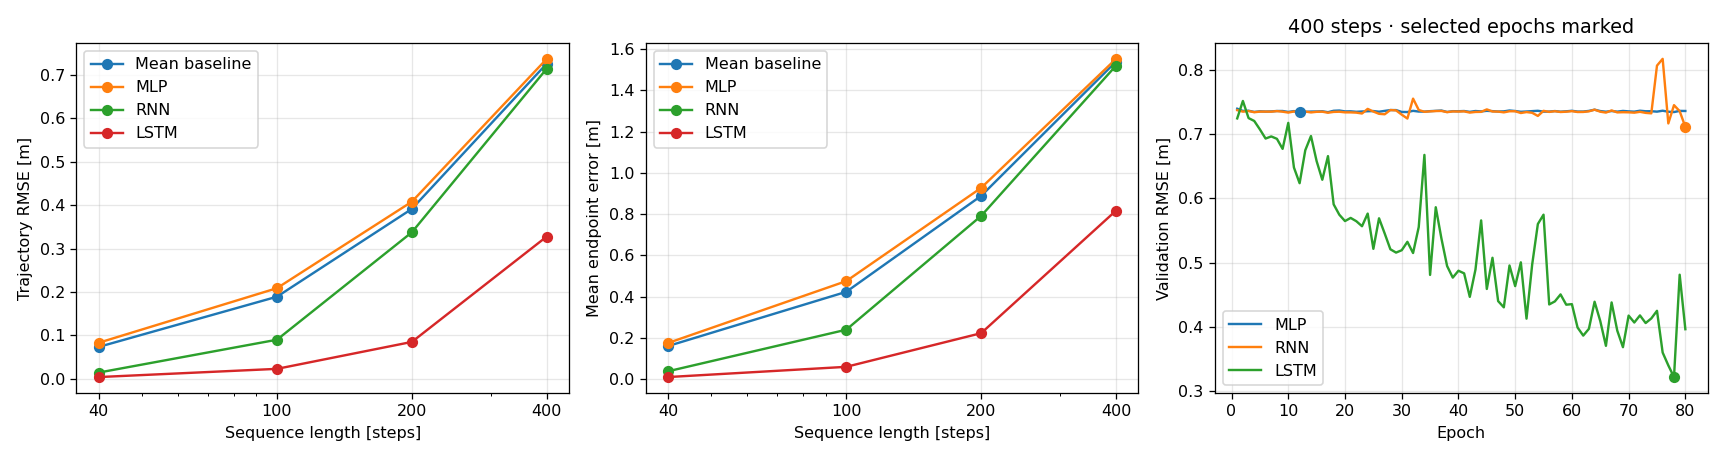

In [6]:
# Step 2 results on matched held-out sequences
for label, values_by_model in [
    ("Trajectory RMSE [m]", results),
    ("Mean endpoint error [m]", endpoint_errors),
]:
    print(label)
    print(f"{'Steps':>5}" + "".join(f"{name:>16}" for name in results))
    for index, length in enumerate(sequence_lengths):
        print(f"{length:>5}" + "".join(
            f"{values[index]:>16.4f}" for values in values_by_model.values()
        ))
    print()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, values_by_model, ylabel in [
    (axes[0], results, "Trajectory RMSE [m]"),
    (axes[1], endpoint_errors, "Mean endpoint error [m]"),
]:
    for name, values in values_by_model.items():
        axis.plot(sequence_lengths, values, marker="o", label=name)
    axis.set_xscale("log")
    axis.set_xticks(sequence_lengths, labels=sequence_lengths)
    axis.set_xlabel("Sequence length [steps]")
    axis.set_ylabel(ylabel)

longest_sequence = max(sequence_lengths)
for name in ["MLP", "RNN", "LSTM"]:
    key = (name, longest_sequence)
    curve = validation_curves[key]
    best_epoch = selected_epochs[key]
    line, = axes[2].plot(range(1, epochs + 1), curve, label=name)
    axes[2].scatter(best_epoch, curve[best_epoch - 1], color=line.get_color(), zorder=3)
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Validation RMSE [m]")
axes[2].set_title(f"{longest_sequence} steps · selected epochs marked")

for axis in axes:
    axis.legend()
    axis.grid(alpha=0.3)

fig.tight_layout()
plt.show()

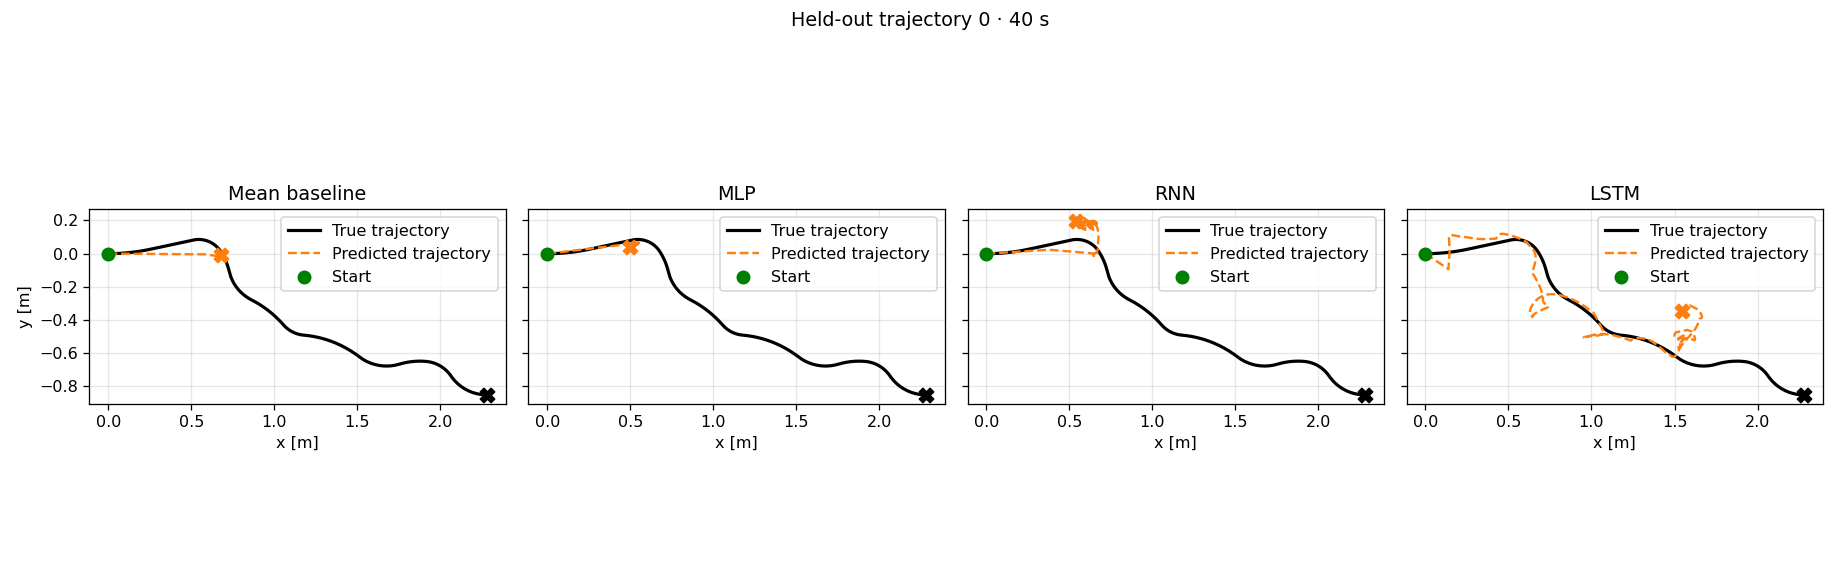

In [7]:
# Visualize a sample trajectory prediction

sequence_length = max(sequence_lengths)
sample_index = 0

true_path = trajectories[sequence_length][n_train + n_val + sample_index, :, :2]
model_names = ["Mean baseline", "MLP", "RNN", "LSTM"]
fig, axes = plt.subplots(
    1, len(model_names), figsize=(16, 5), sharex=True, sharey=True
)

for axis, model_name in zip(axes, model_names):
    predicted_position = test_predictions[
        (model_name, sequence_length)
    ][sample_index].numpy()

    # Include the known initial pose for display. Model outputs start at step 1.
    predicted_path = np.vstack([true_path[:1], predicted_position])

    axis.plot(
        true_path[:, 0],
        true_path[:, 1],
        color="black",
        linewidth=2,
        label="True trajectory",
    )
    axis.plot(
        predicted_path[:, 0],
        predicted_path[:, 1],
        "--",
        color="tab:orange",
        label="Predicted trajectory",
    )

    axis.scatter(0, 0, color="green", s=60, label="Start", zorder=3)
    axis.scatter(
        *true_path[-1],
        color="black",
        marker="X",
        s=80,
        zorder=3,
    )
    axis.scatter(
        *predicted_path[-1],
        color="tab:orange",
        marker="X",
        s=80,
        zorder=3,
    )

    axis.set_title(model_name)
    axis.set_xlabel("x [m]")
    axis.set_aspect("equal", adjustable="box")
    axis.grid(alpha=0.3)
    axis.legend()

axes[0].set_ylabel("y [m]")
fig.suptitle(f"Held-out trajectory {sample_index} · {sequence_length * dt:g} s")

plt.tight_layout()
plt.show()